# 02 · Descarga de los espectros de LHS 1140 para LBL

**Idea del cuaderno:** con lo que aprendimos en el 01, aquí ya vamos directo a lo que necesita LBL: buscar todos los espectros de LHS 1140 en ESO, ver cuáles son públicos, mirar qué trae cada paquete de HARPS y de ESPRESSO, y armar una función que baja **solo** el espectro 2D y su blaze (sin guardar todo lo demás, que pesa mucho).

Resumen de lo que pasa:
1. Consulta al archivo de ESO por posición (TAP + ADQL).
2. Conteo por instrumento y revisión de que todo sea público.
3. Qué hay dentro de un producto de HARPS (`.tar` con el `e2ds`).
4. Qué hay dentro de un producto de ESPRESSO (`.tar` con los `S2D` y el blaze).
5. Función `descargar_espresso` y una prueba con 3 espectros.
6. Revisar que el blaze que se bajó es el mismo que dice el encabezado.

Está pensado para correr en **Google Colab** (las últimas celdas montan Drive).

## Librerías y conexión
`pyvo` es el que manda las preguntas al servicio TAP de ESO. `tap` todavía no pregunta nada, solo deja lista la "ventanilla".

In [ ]:
!pip install pyvo -q
import pyvo
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from astropy.time import Time

tap = pyvo.dal.TAPService("https://archive.eso.org/tap_obs")

Coordenadas de LHS 1140 en grados (RA, Dec). Lo dejamos como diccionario por si después queremos meter más sistemas en el mismo ciclo.

In [ ]:
sistemas = {
    "LHS 1140": (11.248632, -15.274109)
}

## Buscar espectros alrededor de la estrella
Buscamos por **posición** (un círculo de 1 arcmin) y no por nombre, porque cada observador escribe el nombre distinto (`LHS1140`, `LHS 1140`, `TOI-256`...).

In [ ]:
def buscar_espectros(ra, dec, radio_arcmin=1.0):
    query = f"""
    SELECT target_name, dp_id, instrument_name, t_min, t_exptime,
           snr, obs_release_date, access_url
    FROM ivoa.ObsCore
    WHERE dataproduct_type = 'spectrum'
      AND CONTAINS(POINT('ICRS', s_ra, s_dec),
                   CIRCLE('ICRS', {ra}, {dec}, {radio_arcmin/60})) = 1
    """
    return tap.search(query, maxrec=20000).to_table().to_pandas()

Corremos la búsqueda y contamos por instrumento.

**Resultado:** 296 de HARPS, 117 de ESPRESSO y 1 de CRIRES. Los 117 de ESPRESSO coinciden con los que usaron Cadieux et al. (2024).

In [ ]:
tablas = []
for nombre, (ra, dec) in sistemas.items():
    df = buscar_espectros(ra, dec)
    df["sistema"] = nombre
    tablas.append(df)

espectros = pd.concat(tablas, ignore_index=True)
espectros["fecha"] = Time(espectros["t_min"], format="mjd").datetime
espectros["instrument_name"].value_counts()

,count
instrument_name,
HARPS,296
ESPRESSO,117
CRIRES,1


## ¿Todo es público?
Nos quedamos con los instrumentos que soporta LBL y comparamos la fecha de liberación con hoy. Sale que **todo es público** (117 de ESPRESSO y 296 de HARPS), así que no hay que pedir permisos.

In [ ]:
INSTR_LBL = ["HARPS", "ESPRESSO", "NIRPS"]
espectros_lbl = espectros[espectros["instrument_name"].isin(INSTR_LBL)].copy()

liberacion = pd.to_datetime(espectros_lbl["obs_release_date"], format="ISO8601", utc=True)
espectros_lbl["publico"] = liberacion <= pd.Timestamp.now(tz="UTC")

pd.crosstab([espectros_lbl["sistema"], espectros_lbl["publico"]],
            espectros_lbl["instrument_name"])

,instrument_name,ESPRESSO,HARPS
sistema,publico,,
LHS 1140,True,117,296


Gráfica de cuándo se tomó cada espectro. Se ve que HARPS cubre varios años (2015–2019) y ESPRESSO solo 2018–2019.

(La figura sale con dos paneles porque el código está hecho para varios sistemas; con LHS 1140 solo se usa el de arriba.)

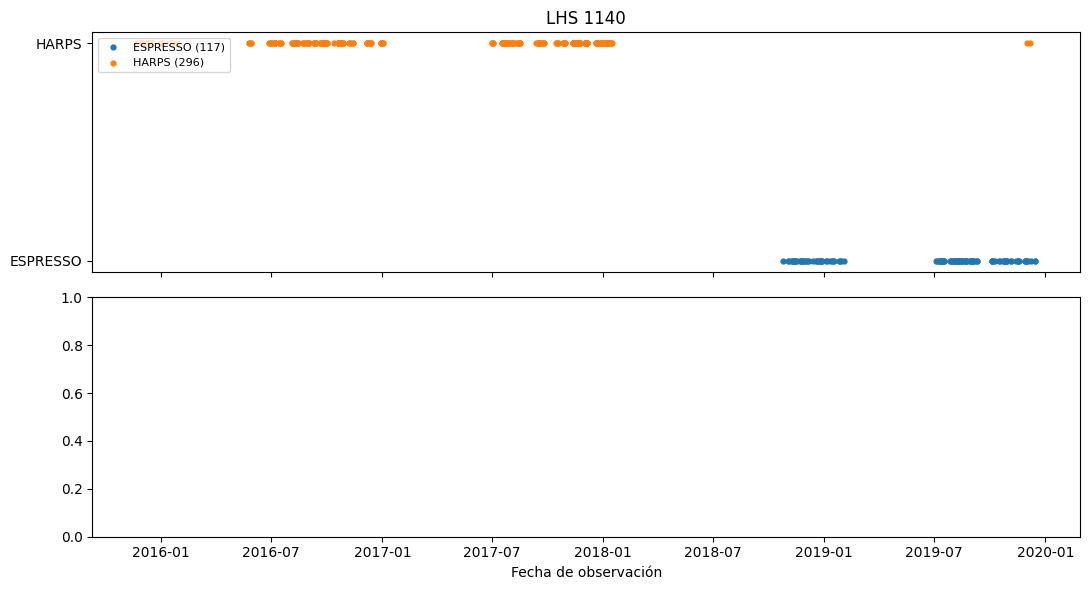

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)

for ax, (nombre, grupo) in zip(axes, espectros_lbl.groupby("sistema")):
    for i, (inst, g) in enumerate(grupo.groupby("instrument_name")):
        ax.scatter(g["fecha"], np.full(len(g), i), s=12, label=f"{inst} ({len(g)})")
    ax.set_yticks(range(grupo["instrument_name"].nunique()))
    ax.set_yticklabels(sorted(grupo["instrument_name"].unique()))
    ax.set_title(nombre)
    ax.legend(loc="upper left", fontsize=8)

axes[-1].set_xlabel("Fecha de observación")
plt.tight_layout()

## Qué trae un producto de HARPS
Cogemos el primer espectro de HARPS y armamos su enlace de **DataLink**, que es la lista de todos los archivos asociados a ese producto.

In [ ]:
harps = espectros_lbl[espectros_lbl["instrument_name"] =='HARPS']
mi_dp_id = harps["dp_id"].iloc[0]
url = "https://archive.eso.org/datalink/links?ID=ivo://eso.org/ID?" + mi_dp_id
print(url)

https://archive.eso.org/datalink/links?ID=ivo://eso.org/ID?ADP.2016-01-04T01:01:59.073


La tabla de DataLink: cada fila es un archivo relacionado (el espectro, un preview, el `.tar` auxiliar, el catálogo de VR de HARPS, etc.).

In [ ]:
from pyvo.dal.adhoc import DatalinkResults
respuesta = DatalinkResults.from_result_url(url)
tabla_links = respuesta.to_table().to_pandas()
tabla_links

,ID,access_url,service_def,error_message,semantics,description,content_type,content_length,eso_origfile,eso_category,eso_datalink
0,ivo://eso.org/ID?ADP.2016-01-04T01:01:59.073,https://dataportal.eso.org/dataPortal/file/ADP...,,,#this,Requested file,application/x-fits-bintable,5264640,HARPS.2016-01-03T00:41:43.897_s1d_A_DRS_HARPS_...,SCIENCE.SPECTRUM,https://archive.eso.org/datalink/links?ID=ivo:...
1,ivo://eso.org/ID?ADP.2016-01-04T01:01:59.073,,ADP.2016-01-04T01:01:59.073_soda,,#cutout,Cutout of #this (SODA-sync),application/x-fits-bintable,<NA>,,,
2,ivo://eso.org/ID?ADP.2016-01-04T01:01:59.073,https://archive.eso.org/previews/v1/files/ADP....,,,#preview,PDF preview of the requested file,application/pdf,1000000,,,
3,ivo://eso.org/ID?ADP.2016-01-04T01:01:59.073,https://archive.eso.org/dataset/ADP.2016-01-04...,,,#preview,HTML representation of the dataset,text/html,1000000,,,
4,ivo://eso.org/ID?ADP.2016-01-04T01:01:59.073,https://dataportal.eso.org/dataPortal/file/ADP...,,,#auxiliary,Ancillary file associated to the requested file,application/x-tar,6963200,HARPS.2016-01-03T00:41:43.897_DRS_HARPS_3.8.tar,ANCILLARY.HARPSTAR,https://archive.eso.org/datalink/links?ID=ivo:...
5,ivo://eso.org/ID?ADP.2016-01-04T01:01:59.073,https://dataportal.eso.org/dataPortal/file/HAR...,,,#progenitor,File used to generate the requested file (proc...,application/fits,11001141,,,https://archive.eso.org/datalink/links?ID=ivo:...
6,ivo://eso.org/ID?ADP.2016-01-04T01:01:59.073,https://dataportal.eso.org/dataPortal/file/ADP...,,,#derivation,Science product derived from the requested file,application/fits,167607360,HARPS_RVCAT_2023_DR1.fits,SCIENCE.CATALOG,https://archive.eso.org/datalink/links?ID=ivo:...
7,ivo://eso.org/ID?ADP.2016-01-04T01:01:59.073,https://archive.eso.org/datalink/links?ID=ivo:...,,,http://archive.eso.org/rdf/datalink/eso#data_d...,Release description of the collection the requ...,application/pdf,1000000,,,


In [ ]:
pd.set_option("display.max_colwidth", None)   # esta línea es [COPIAR]: evita que corte los nombres largos
tabla_links[['semantics','description','content_length','eso_origfile']]

,semantics,description,content_length,eso_origfile
0,#this,Requested file,5264640,HARPS.2016-01-03T00:41:43.897_s1d_A_DRS_HARPS_3.8_ESOSDP.fits
1,#cutout,Cutout of #this (SODA-sync),<NA>,
2,#preview,PDF preview of the requested file,1000000,
3,#preview,HTML representation of the dataset,1000000,
4,#auxiliary,Ancillary file associated to the requested file,6963200,HARPS.2016-01-03T00:41:43.897_DRS_HARPS_3.8.tar
5,#progenitor,File used to generate the requested file (processing provenance),11001141,
6,#derivation,Science product derived from the requested file,167607360,HARPS_RVCAT_2023_DR1.fits
7,http://archive.eso.org/rdf/datalink/eso#data_documentation,Release description of the collection the requested file belongs to,1000000,


Bajamos el `.tar` auxiliar (~7 MB) y listamos lo que tiene adentro sin descomprimir. Ahí está el **`e2ds_A`**, que es el espectro por órdenes que necesita LBL.

In [ ]:
import tarfile
from astropy.utils.data import download_file

# 1) Fila del paquete .tar y su enlace de descarga
fila_tar = tabla_links[tabla_links["eso_origfile"].str.contains(".tar", na=False)]
url_tar = fila_tar["access_url"].iloc[0]
print("Enlace:", url_tar)

# 2) Descargar (con cache=True no lo vuelve a bajar si ya existe)
ruta_tar = download_file(url_tar, cache=True)
print("Guardado en:", ruta_tar)

# 3) Listar lo que hay adentro, sin descomprimir
with tarfile.open(ruta_tar) as paquete:
    for nombre in paquete.getnames():
        print(nombre)

Enlace: https://dataportal.eso.org/dataPortal/file/ADP.2016-01-04T01:01:58.893
Guardado en: /root/.astropy/cache/download/url/8ead298786c4960644a724c765d13d72/contents
data/reduced/2016-01-02/HARPS.2016-01-03T00:41:43.897_INT_GUIDE.fits
data/reduced/2016-01-02/HARPS.2016-01-03T00:41:43.897_bis_M2_A.fits
data/reduced/2016-01-02/HARPS.2016-01-03T00:41:43.897_bis_M2_B.fits
data/reduced/2016-01-02/HARPS.2016-01-03T00:41:43.897_ccf_M2_A.fits
data/reduced/2016-01-02/HARPS.2016-01-03T00:41:43.897_ccf_M2_A.tbl
data/reduced/2016-01-02/HARPS.2016-01-03T00:41:43.897_ccf_M2_B.fits
data/reduced/2016-01-02/HARPS.2016-01-03T00:41:43.897_ccf_M2_B.tbl
data/reduced/2016-01-02/HARPS.2016-01-03T00:41:43.897_e2ds_A.fits
data/reduced/2016-01-02/HARPS.2016-01-03T00:41:43.897_e2ds_B.fits
data/reduced/2016-01-02/HARPS.2016-01-03T00:41:43.897_s1d_A.fits
data/reduced/2016-01-02/HARPS.2016-01-03T00:41:43.897_s1d_B.fits


Sacamos solo el `e2ds_A` y miramos el encabezado.

**Lo importante:** es una imagen de **72 órdenes × 4096 píxeles**, y el header dice qué **blaze** usó el pipeline (`HARPS.2016-01-02T16:22:20.139_blaze_A.fits`). Ese blaze **no viene en el `.tar`** ni está en el archivo de ESO; por eso al final usamos el blaze que preparó Camilo (ver informe, sección II.C).

In [ ]:
from astropy.io import fits

# Sacar solo el e2ds_A del paquete
with tarfile.open(ruta_tar) as paquete:
    nombre_e2ds = [n for n in paquete.getnames() if "e2ds_A" in n][0]
    paquete.extract(nombre_e2ds, path="espectros", filter="data")
ruta_e2ds = "espectros/" + nombre_e2ds

with fits.open(ruta_e2ds) as hdul:
    hdul.info()
    datos = hdul[0].data
    h = hdul[0].header

print("Forma (órdenes, píxeles):", datos.shape)
print("Objeto:  ", h.get("OBJECT"))
print("MJD-OBS: ", h.get("MJD-OBS"))
print("Blaze:   ", h.get("HIERARCH ESO DRS BLAZE FILE"))
print("SNR orden 50:", h.get("HIERARCH ESO DRS SPE EXT SN50"))

Filename: espectros/data/reduced/2016-01-02/HARPS.2016-01-03T00:41:43.897_e2ds_A.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU    3056   (4096, 72)   float32   
Forma (órdenes, píxeles): (72, 4096)
Objeto:   LHS1140
MJD-OBS:  57390.02898029
Blaze:    HARPS.2016-01-02T16:22:20.139_blaze_A.fits
SNR orden 50: 10.8


Lo mismo de la tabla de DataLink pero impreso fila por fila, para leer bien los nombres y tamaños.

In [ ]:
for i, fila in tabla_links.iterrows():
    print(f"--- Fila {i} ---")
    print("semantics:   ", fila["semantics"])
    print("categoría:   ", fila["eso_category"])
    print("archivo:     ", fila["eso_origfile"])
    print("tamaño (MB): ", round(fila["content_length"] / 1e6, 1) if pd.notna(fila["content_length"]) else "—")
    print("descripción: ", fila["description"])
    print("enlace:      ", fila["access_url"])
    print()

--- Fila 0 ---
semantics:    #this
categoría:    SCIENCE.SPECTRUM
archivo:      HARPS.2016-01-03T00:41:43.897_s1d_A_DRS_HARPS_3.8_ESOSDP.fits
tamaño (MB):  5.3
descripción:  Requested file
enlace:       https://dataportal.eso.org/dataPortal/file/ADP.2016-01-04T01:01:59.073

--- Fila 1 ---
semantics:    #cutout
categoría:    
archivo:      
tamaño (MB):  —
descripción:  Cutout of #this (SODA-sync)
enlace:       

--- Fila 2 ---
semantics:    #preview
categoría:    
archivo:      
tamaño (MB):  1.0
descripción:  PDF preview of the requested file
enlace:       https://archive.eso.org/previews/v1/files/ADP.2016-01-04T01:01:59.073/preview?format=DOWNLOAD

--- Fila 3 ---
semantics:    #preview
categoría:    
archivo:      
tamaño (MB):  1.0
descripción:  HTML representation of the dataset
enlace:       https://archive.eso.org/dataset/ADP.2016-01-04T01:01:59.073

--- Fila 4 ---
semantics:    #auxiliary
categoría:    ANCILLARY.HARPSTAR
archivo:      HARPS.2016-01-03T00:41:43.897_DRS_HARPS_3.8.

Conteo por colección hecho directamente en el servidor (`GROUP BY`). Da lo mismo de antes: 117 ESPRESSO y 296 HARPS.

In [ ]:
ra, dec = sistemas["LHS 1140"]

query = f"""
SELECT obs_collection, instrument_name, COUNT(*) AS n
FROM ivoa.ObsCore
WHERE dataproduct_type = 'spectrum'
  AND instrument_name IN ('HARPS', 'ESPRESSO')
  AND CONTAINS(POINT('ICRS', s_ra, s_dec),
               CIRCLE('ICRS', {ra}, {dec}, {1.0/60})) = 1
GROUP BY obs_collection, instrument_name
"""
colecciones = tap.search(query).to_table().to_pandas()
colecciones

,obs_collection,instrument_name,n
0,ESPRESSO,ESPRESSO,117
1,HARPS,HARPS,296


## Qué trae un producto de ESPRESSO
Función pequeña para ver los enlaces de un producto. En ESPRESSO el paquete que nos sirve es el **`ANCILLARY.2DECHELLE.TAR`** (~137 MB), que trae los espectros 2D.

In [ ]:
def ver_links(dp_id):
    url = "https://archive.eso.org/datalink/links?ID=ivo://eso.org/ID?" + dp_id
    tabla = DatalinkResults.from_result_url(url).to_table().to_pandas()
    for i, fila in tabla.iterrows():
        tam = round(fila["content_length"] / 1e6, 1) if pd.notna(fila["content_length"]) else "—"
        print(f"[{i}] {fila['semantics']} | {fila['eso_category']} | {tam} MB")
        print(f"     {fila['eso_origfile']}")
    return tabla

espresso = espectros_lbl[espectros_lbl["instrument_name"] == "ESPRESSO"]
links_espresso = ver_links(espresso["dp_id"].iloc[0])

[0] #this | SCIENCE.SPECTRUM | 37.4 MB
     ES_SFLX_2301294_2019-07-28T06:09:10.095_HR_2x1_U3.fits
[1] #cutout |  | — MB
     
[2] #preview |  | 1.0 MB
     
[3] #preview |  | 1.0 MB
     
[4] #auxiliary | ANCILLARY.SPECTRUM | 19.6 MB
     ES_SFLB_2301294_2019-07-28T06:09:10.095_HR_2x1_U3.fits
[5] #auxiliary | ANCILLARY.CCF | 0.3 MB
     ES_SCCA_2301294_2019-07-28T06:09:10.095_HR_2x1_U3.fits
[6] #auxiliary | ANCILLARY.DRIFT | 6.3 MB
     ES_SDMB_2301294_2019-07-28T06:09:10.095_HR_2x1_U3.fits
[7] #auxiliary | ANCILLARY.2DECHELLE.TAR | 136.7 MB
     ES_SFLX_2301294_2019-07-28T06:09:10.095_HR_2x1_U3.tar
[8] #auxiliary | ANCILLARY.PREVIEW | 0.2 MB
     r.ESPRE.2019-07-28T06:09:10.095_0000.png
[9] #progenitor |  | 92.7 MB
     
[10] http://archive.eso.org/rdf/datalink/eso#data_documentation |  | 1.0 MB
     


Contenido del `.tar` 2D de ESPRESSO:
- `ES_S2DA_...`: espectro 2D de la fibra A.
- `ES_S2BA_...`: espectro 2D de la fibra A en su versión "con blaze" (`S2D_BLAZE_A`).
- `ES_PFBA_...`: el **blaze** de esa noche.

O sea, a diferencia de HARPS, **ESPRESSO sí trae el blaze en el paquete**.

In [ ]:
fila_2d = links_espresso[links_espresso["eso_category"] == "ANCILLARY.2DECHELLE.TAR"]
url_2d = fila_2d["access_url"].iloc[0]

ruta_tar_es = download_file(url_2d, cache=True)   # ~137 MB, puede tardar un poco

with tarfile.open(ruta_tar_es) as paquete:
    for miembro in paquete.getmembers():
        print(f"{miembro.size/1e6:7.1f} MB   {miembro.name}")

   65.2 MB   ES_S2DA_2301294_2019-07-28T06:09:10.095_HR_2x1_U3.fits
   65.2 MB   ES_S2BA_2301294_2019-07-28T06:09:10.095_HR_2x1_U3.fits
    6.3 MB   ES_PFBA_190727A_HR_2x1.fits


Abrimos los tres archivos para ver qué son. Los espectros son de **170 órdenes × 9111 píxeles** y ya traen la longitud de onda en extensiones aparte (`WAVEDATA_...`).

In [ ]:
with tarfile.open(ruta_tar_es) as paquete:
    paquete.extractall(path="espectros_es", filter="data")
    nombres_es = paquete.getnames()

for nombre in nombres_es:
    ruta = "espectros_es/" + nombre
    print("=" * 70)
    print(nombre)
    with fits.open(ruta) as hdul:
        h0 = hdul[0].header
        print("  Categoría:", h0.get("HIERARCH ESO PRO CATG"))
        print("  Objeto:   ", h0.get("OBJECT"))
        print("  Extensiones:")
        for ext in hdul:
            forma = ext.data.shape if ext.data is not None else "—"
            print(f"     {ext.name:12s} {forma}")

ES_S2DA_2301294_2019-07-28T06:09:10.095_HR_2x1_U3.fits
  Categoría: S2D_A
  Objeto:    LHS1140
  Extensiones:
     PRIMARY      —
     SCIDATA      (170, 9111)
     ERRDATA      (170, 9111)
     QUALDATA     (170, 9111)
     WAVEDATA_VAC_BARY (170, 9111)
     WAVEDATA_AIR_BARY (170, 9111)
     DLLDATA_VAC_BARY (170, 9111)
     DLLDATA_AIR_BARY (170, 9111)
ES_S2BA_2301294_2019-07-28T06:09:10.095_HR_2x1_U3.fits
  Categoría: S2D_BLAZE_A
  Objeto:    LHS1140
  Extensiones:
     PRIMARY      —
     SCIDATA      (170, 9111)
     ERRDATA      (170, 9111)
     QUALDATA     (170, 9111)
     WAVEDATA_VAC_BARY (170, 9111)
     WAVEDATA_AIR_BARY (170, 9111)
     DLLDATA_VAC_BARY (170, 9111)
     DLLDATA_AIR_BARY (170, 9111)
ES_PFBA_190727A_HR_2x1.fits
  Categoría: BLAZE_A
  Objeto:    FLAT,LAMP,OFF
  Extensiones:
     PRIMARY      —
                  (170, 9111)


## Función de descarga
Aquí está la configuración y la función `descargar_espresso`, que:
1. busca el `.tar` 2D del producto,
2. lo baja,
3. guarda solo el espectro de ciencia en `science/LHS1140/` y el blaze en `calib/` (que es la estructura de carpetas que pide LBL),
4. y borra el `.tar` para no llenar el disco.

Si un blaze ya está en `calib/` no lo repite, porque varias noches pueden compartir el mismo.

> **Ojo:** en esta versión `GUARDAR_CIENCIA = ["ES_S2BA"]`. Los espectros que finalmente corrimos en LBL (carpeta `science/` del computador) son los **`ES_S2DA`**, así que para repetir el análisis hay que cambiar esa línea como dice el comentario.

(El código termina en `# ---- CORRER` porque la parte de correr quedó en la celda siguiente.)

In [ ]:
import os

# ---------------- CONFIGURACIÓN ----------------
DATA_DIR    = "DATA_DIR"
SCIENCE_DIR = os.path.join(DATA_DIR, "science", "LHS1140")
CALIB_DIR   = os.path.join(DATA_DIR, "calib")

GUARDAR_CIENCIA = ["ES_S2BA"]   # cambia a ["ES_S2DA"] o ["ES_S2DA", "ES_S2BA"] según lo que pida LBL
GUARDAR_CALIB   = ["ES_PFBA"]   # blaze

FECHA_CORTE = pd.Timestamp("2019-06-27")   # intervención de ESPRESSO: CONFIRMAR fecha exacta en Cadieux et al. 2024
N_PRUEBA    = 3                             # cuántos espectros bajar en esta prueba
# ------------------------------------------------

os.makedirs(SCIENCE_DIR, exist_ok=True)
os.makedirs(CALIB_DIR, exist_ok=True)

def descargar_espresso(dp_id):
    """Baja el .tar 2D de un espectro, guarda solo lo necesario y borra el .tar."""
    url = "https://archive.eso.org/datalink/links?ID=ivo://eso.org/ID?" + dp_id
    links = DatalinkResults.from_result_url(url).to_table().to_pandas()
    fila = links[links["eso_category"] == "ANCILLARY.2DECHELLE.TAR"]
    if len(fila) == 0:
        return None, None

    ruta_tar = download_file(fila["access_url"].iloc[0], cache=False)
    archivo_ciencia, archivo_blaze = None, None

    with tarfile.open(ruta_tar) as paquete:
        for m in paquete.getmembers():
            base = os.path.basename(m.name)
            if any(base.startswith(p) for p in GUARDAR_CIENCIA):
                destino = SCIENCE_DIR
                archivo_ciencia = base
            elif any(base.startswith(p) for p in GUARDAR_CALIB):
                destino = CALIB_DIR
                archivo_blaze = base
                if os.path.exists(os.path.join(CALIB_DIR, base)):   # blaze compartido: no repetir
                    continue
            else:
                continue
            m.name = base   # quitar subcarpetas internas del .tar
            paquete.extract(m, path=destino, filter="data")

    os.remove(ruta_tar)   # liberar espacio
    return archivo_ciencia, archivo_blaze

# ---------------- CORRER

## Prueba con 3 espectros
Baja los primeros `N_PRUEBA = 3` y guarda un registro (`registro_espresso.csv`) con qué se bajó y si es de antes o después del corte.

**Resultado:** los 3 son de 2018, o sea de **antes** de la intervención de ESPRESSO de junio de 2019. Era solo para probar que la función sirve; para el análisis usamos los espectros **posteriores** a junio de 2019 (44 al final, ver informe sección II.A).

In [ ]:
esp = espectros_lbl[(espectros_lbl["instrument_name"] == "ESPRESSO") &
                    (espectros_lbl["publico"])].sort_values("fecha")
print("Espectros de ESPRESSO disponibles:", len(esp))

registro = []
for _, fila in esp.head(N_PRUEBA).iterrows():
    print("Descargando", fila["dp_id"], fila["fecha"])
    ciencia, blaze = descargar_espresso(fila["dp_id"])
    print("   ciencia:", ciencia, "| blaze:", blaze)
    registro.append({
        "dp_id": fila["dp_id"],
        "fecha": fila["fecha"],
        "snr": fila["snr"],
        "instrumento": "ESPRESSO",
        "bloque": "antes" if fila["fecha"] < FECHA_CORTE else "despues",
        "archivo_ciencia": ciencia,
        "archivo_blaze": blaze,
    })

tabla_registro = pd.DataFrame(registro)
tabla_registro.to_csv(os.path.join(DATA_DIR, "registro_espresso.csv"), index=False)
tabla_registro

Espectros de ESPRESSO disponibles: 117
Descargando ADP.2021-04-13T12:52:06.131 2018-10-25 04:41:44.272320
   ciencia: ES_S2BA_2094771_2018-10-25T04:41:44.272_HR_2x1_U3.fits | blaze: ES_PFBA_181024A_HR_2x1.fits
Descargando ADP.2021-04-14T13:24:26.107 2018-11-02 01:27:10.090944
   ciencia: ES_S2BA_2100236_2018-11-02T01:27:10.091_HR_2x1_U3.fits | blaze: ES_PFBA_181101A_HR_2x1.fits
Descargando ADP.2021-04-14T13:31:15.314 2018-11-03 00:18:39.377664
   ciencia: ES_S2BA_2100239_2018-11-03T00:18:39.378_HR_2x1_U3.fits | blaze: ES_PFBA_181102A_HR_2x1.fits


,dp_id,fecha,snr,instrumento,bloque,archivo_ciencia,archivo_blaze
0,ADP.2021-04-13T12:52:06.131,2018-10-25 04:41:44.272320,25.8,ESPRESSO,antes,ES_S2BA_2094771_2018-10-25T04:41:44.272_HR_2x1_U3.fits,ES_PFBA_181024A_HR_2x1.fits
1,ADP.2021-04-14T13:24:26.107,2018-11-02 01:27:10.090944,27.1,ESPRESSO,antes,ES_S2BA_2100236_2018-11-02T01:27:10.091_HR_2x1_U3.fits,ES_PFBA_181101A_HR_2x1.fits
2,ADP.2021-04-14T13:31:15.314,2018-11-03 00:18:39.377664,29.0,ESPRESSO,antes,ES_S2BA_2100239_2018-11-03T00:18:39.378_HR_2x1_U3.fits,ES_PFBA_181102A_HR_2x1.fits


## ¿El blaze que se bajó es el correcto?
Buscamos en el header del espectro todas las claves que mencionan "BLAZE" y listamos lo que quedó en `calib/`.

In [ ]:
ruta_prueba = os.path.join(SCIENCE_DIR, tabla_registro["archivo_ciencia"].iloc[0])
h = fits.getheader(ruta_prueba, ext=0)

for clave, valor in h.items():
    if "BLAZE" in str(valor).upper() or "BLAZE" in clave.upper():
        catg_clave = clave.replace("NAME", "CATG")
        print(f"{clave} = {valor}")

print("\nArchivos en calib/:", os.listdir(CALIB_DIR))

ESO PRO CATG = S2D_BLAZE_A
ESO PRO REC1 CAL12 CATG = BLAZE_A
ESO PRO REC1 CAL13 CATG = BLAZE_B
ESO PRO REC1 CAL20 CATG = S2D_BLAZE_THAR_FP_B

Archivos en calib/: ['ES_PFBA_181024A_HR_2x1.fits', 'ES_PFBA_181102A_HR_2x1.fits', 'ES_PFBA_181101A_HR_2x1.fits']


Comparamos el nombre del blaze que pide el encabezado (`CAL12 NAME`) con el archivo que guardamos. **Coinciden** (`ES_PFBA_181024A_HR_2x1.fits`), así que LBL va a encontrar el blaze que le corresponde a cada espectro.

In [ ]:
print("Nombre del blaze en el encabezado:", h.get("HIERARCH ESO PRO REC1 CAL12 NAME"))
print("Nombre guardado en calib/:        ", tabla_registro["archivo_blaze"].iloc[0])

h_blaze = fits.getheader(os.path.join(CALIB_DIR, tabla_registro["archivo_blaze"].iloc[0]))
print("Nombre interno del blaze:         ", h_blaze.get("PIPEFILE"), "|", h_blaze.get("ARCFILE"))

Nombre del blaze en el encabezado: ES_PFBA_181024A_HR_2x1.fits
Nombre guardado en calib/:         ES_PFBA_181024A_HR_2x1.fits
Nombre interno del blaze:          r.ESPRE.2018-10-25T10:23:33.378_tpl_0003.fits | M.ESPRESSO.2020-08-20T12:17:29.700.fits


## Guardar en Drive
En Colab lo que se baja se borra al cerrar la sesión, por eso montamos Drive y apuntamos `DATA_DIR` a una carpeta de ahí. Para correr la descarga completa hay que volver a correr la celda de configuración/descarga después de cambiar `DATA_DIR`.

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
DATA_DIR = "/content/drive/MyDrive/LHS1140/DATA_DIR"